# 06. Seasonality

Is there any statistically detectable pattern in returns of the SP500 tied to the day of the week or the month?

The scope of this analysis will only be the SP500 index return series, as the market. It provides a clean time series.
No per sector nor per stock analysis will be performed.

In [ ]:
import pandas as pd
import numpy as np
from scipy import stats
from pathlib import Path
import matplotlib.pyplot as plt


"\nI could define something like:\n\npd.set_option('display.float_format', lambda x: f'{x:.6f}')\n#this basically is telling pandas: whenever you display floating-point numbers, format them using this function\n# pd.set_option(...) - a Pandas function for changing settings\n# 'display.float_format' - the name of a specific Pandas option\n# f'{x:.6f}' means:\n#   f'...' - is telling that what follows is a string and whatever is inside {} needs to be transformed\n#   x - put the value of x here\n#   : - introduces a format specification\n#   .6 - 6 digits after the decimal point.\n#   f (last f) - format the number as a floating-point number.\n\n\n\nBAR_COLOR = '#4C72B0'\nZERO_LINE_COLOR = '#888888'\n#these are just defining the colors for the elements of the graphs, instead of doing that inside the plot func.\n\n"

Loading data index_features csv:

In [ ]:
source= Path(r"filepath\csv_features")


index_features=pd.read_csv(source / "index_features.csv", parse_dates=["date"], date_format="%Y-%m-%d" )

#dropping null simple returns to use as the base table:
returns= index_features.dropna(subset=["simple_return"]).copy()

#show excess kurtosis and skewness of the index (returns table):
from scipy.stats import skew, kurtosis

print(skew(returns["simple_return"], bias=True), kurtosis(returns["simple_return"], bias=True))


-0.5282979381346664 14.604337290193449


#### 6.1 Day of week summary

In [ ]:
#sort the values by date and add the sq_return column.
#after that, group by the data and calculate all of our stats.
returns = returns.sort_values('date')

returns["sq_return"]=returns["simple_return"]**2

dow_stats=(
    returns
    .groupby("day_of_week")
    .agg(
        day_name=("day_name",'first'),
        #since each group (by day of the week) only has one day of the week, the first/last/min/max return the same value. 
        #Need this trick because because agg() requires an agg func.
        n_obs=("date","size"), #or count would give the same because we removed NaNs.
        mean_return=("simple_return","mean"),
        median_return=("simple_return","median"),
        stddev_return=("simple_return","std"),
        mean_sq_return=("sq_return","mean"),
        #mean_sq_return is a volatility proxy, not volatility itself. Squaring a return removes its sign 
        # the same way variance does, so a DOW with a higher average squared return moved more that day 
        # on average, regardless of direction. It's a quick, simple stand-in for "how much movement happened"
        # without needing a full variance calculation per cell just to eyeball a pattern.
        #Why the proxy:
        # Mean squared return E(R^2)=VAR(R) + (E(R))^2  squared mean return
        #Since daily mean returns are generally very small, their squared values are often negligible relative 
        # to the variance. So the eq can be simplified to E(R^2)=VAR(R)
        min_return=("simple_return","min"),
        max_return=("simple_return","max")
    )
    .reset_index()
    .sort_values("day_of_week")
)

dow_stats

,day_of_week,day_name,n_obs,mean_return,median_return,stddev_return,mean_sq_return,min_return,max_return
0,0,Monday,468,0.000380,0.000950,0.012260,0.000150,-0.119841,0.070331
1,1,Tuesday,518,0.000550,0.000238,0.010697,0.000115,-0.043237,0.093828
2,2,Wednesday,517,0.000608,0.000712,0.010752,0.000116,-0.051831,0.049594
3,3,Thursday,508,0.000296,0.000450,0.011319,0.000128,-0.095113,0.062414
4,4,Friday,505,0.000556,0.000725,0.011160,0.000125,-0.043360,0.092871


#### 6.2 By month summary

Here, grouping by month is pooling every daily return that occurred in that calendar month across all years.
So all januaries' returns of all years are grouped together.
This is to see if daily returns depend on which month they respect to.  
Comparing months (Jan vs Feb) is not the goal here.


In [ ]:
#I already have the returns df with the squared simple returns and ordered by date.
#I need to group by month now.
#Then i need to get the stats (n_obs, mean, median, stddev, mean_sq_return,min_return and max_return)

month_stats=(
    returns
    .groupby("month")
    .agg(
        n_obs=("simple_return","size"),
        mean_return=('simple_return', 'mean'),
        median_return=('simple_return', 'median'),
        stddev_return=('simple_return', 'std'),
        mean_sq_return=('sq_return', 'mean'),
        min_return=('simple_return', 'min'),
        max_return=('simple_return', 'max'),
    )
    .reset_index()
    .sort_values("month")
)

#to get the month names column:
month_stats["month_name"] = pd.to_datetime(month_stats["month"], format="%m").dt.month_name()

month_stats

,month,n_obs,mean_return,median_return,stddev_return,mean_sq_return,min_return,max_return,month_name
0,1,202,0.000412,0.000816,0.009939,0.000098,-0.025678,0.034336,January
1,2,192,0.000087,0.000623,0.010849,0.000117,-0.044163,0.022373,February
2,3,220,0.000414,0.000013,0.020488,0.000418,-0.119841,0.093828,March
3,4,206,0.000610,0.000556,0.011545,0.000133,-0.044142,0.070331,April
4,5,212,0.000472,0.000191,0.009885,0.000097,-0.040395,0.031501,May
5,6,212,0.000550,0.001000,0.010321,0.000106,-0.058944,0.030563,June
6,7,210,0.001586,0.001619,0.007195,0.000054,-0.023149,0.027628,July
7,8,223,0.000064,0.000493,0.009696,0.000094,-0.039414,0.039034,August
8,9,204,-0.000951,0.000007,0.010014,0.000101,-0.043237,0.025083,September
9,10,220,0.000568,0.000170,0.010085,0.000102,-0.035288,0.030584,October


#### 6.3 Visual of the pattern

6.3.1 - DoW graphs:

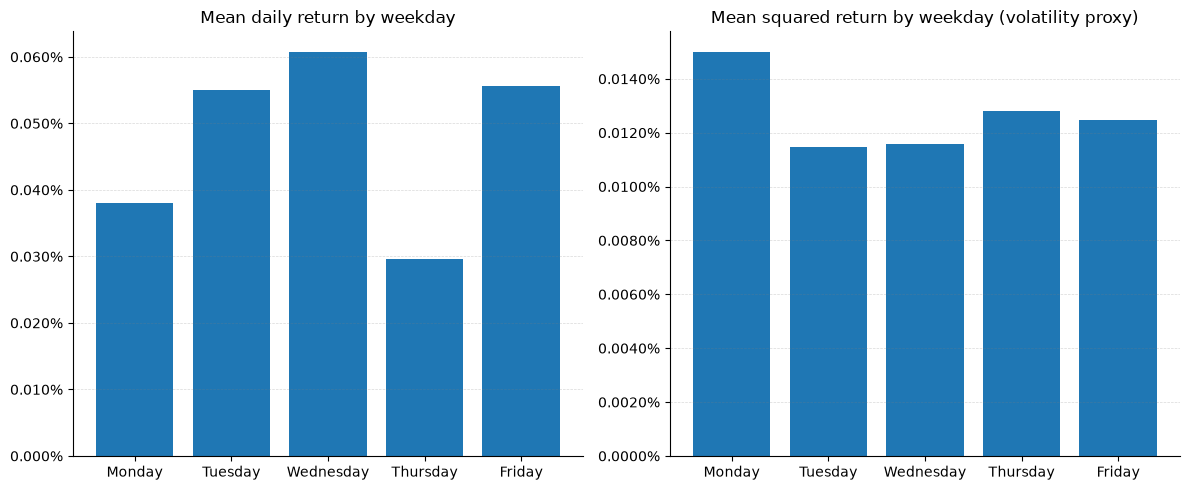

In [ ]:
fig, axes= plt.subplots(1,2, figsize=(12, 5))

"""First graph - DOW mean return graph"""

axes[0].bar(dow_stats["day_name"],dow_stats["mean_return"])

axes[0].set_title("Mean daily return by weekday")

from matplotlib.ticker import PercentFormatter 
#to format the axis scale with percentages

axes[0].yaxis.set_major_formatter(PercentFormatter(1))
#the (1) is to tell that the value 1.0 represents 100%

#to add the grid lines:
axes[0].grid(axis='y', color='gray', linestyle='--', linewidth=0.5, alpha=0.3)

#to remove outer limits, in this case, the top and right ones
axes[0].spines[['top', 'right']].set_visible(False)

"""Second graph: DOW sq mean return graph:"""

axes[1].bar(dow_stats["day_name"],dow_stats["mean_sq_return"])
axes[1].set_title('Mean squared return by weekday (volatility proxy)')
axes[1].yaxis.set_major_formatter(PercentFormatter(1))
axes[1].spines[['top', 'right']].set_visible(False)
axes[1].grid(axis='y', color='gray', linestyle='--', linewidth=0.5, alpha=0.3)

plt.tight_layout()
plt.show()

In [24]:
dow_stats

,day_of_week,day_name,n_obs,mean_return,median_return,stddev_return,mean_sq_return,min_return,max_return
0,0,Monday,468,0.000380,0.000950,0.012260,0.000150,-0.119841,0.070331
1,1,Tuesday,518,0.000550,0.000238,0.010697,0.000115,-0.043237,0.093828
2,2,Wednesday,517,0.000608,0.000712,0.010752,0.000116,-0.051831,0.049594
3,3,Thursday,508,0.000296,0.000450,0.011319,0.000128,-0.095113,0.062414
4,4,Friday,505,0.000556,0.000725,0.011160,0.000125,-0.043360,0.092871


- Wednesday has the highest observed mean return
- Wednesday > Friday = Tuesday > Monday > Thursday
- Monday has the highest observed volatility
- Thursday appears to offer the weakest return/risk tradeoff.


6.3.2 - Month graphs:

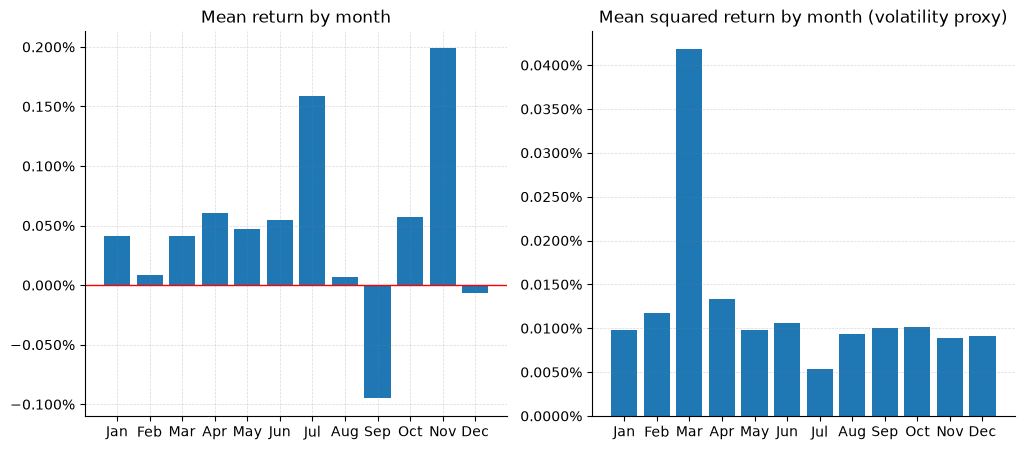

'\nIf i only had one plot:\n\nplt.figure(figsize=(6, 5))\nplt.bar(month_stats["month_name"].str[:3], month_stats["mean_return"])\n\nor\n\nfig, ax = plt.subplots(figsize=(6, 5))\nax.bar(month_stats["month_name"].str[:3], month_stats["mean_return"])\n\n'

In [ ]:
fig,axes=plt.subplots(1,2,figsize=(12,5))

"""1st graph: Month simple return:"""

axes[0].bar(month_stats["month_name"].str[:3],month_stats["mean_return"])
axes[0].axhline(0, color="red", linewidth=1)
axes[0].set_title("Mean return by month")
axes[0].yaxis.set_major_formatter(PercentFormatter(1))
axes[0].grid(axis='both', color='gray', linestyle='--', linewidth=0.5, alpha=0.3)
axes[0].spines[["top","right"]].set_visible(False)

"""2nd graph: Month simple return:"""
axes[1].bar(month_stats["month_name"].str[:3], month_stats["mean_sq_return"])
axes[1].yaxis.set_major_formatter(PercentFormatter(1))
axes[1].grid(axis="y",color="gray",linewidth=0.5, linestyle='--', alpha=0.3)
axes[1].set_title("Mean squared return by month (volatility proxy)")
axes[1].spines[["top","right"]].set_visible(False)

plt.tight_layout
plt.show()


- November has the highest observed mean daily return
- July combines a relatively high observed mean daily return with the lowest volatility proxy
- September is the only notably negative month in the sample
- extraordinarily high March volatility

#### 6.4 Testing the patterns:

A chart does not prove whether the differences it presents are real or just noise, statistically speaking.

There are two interesting questions that require their own test:

1. Does the avg return differ across groups? (metric: mean)
2. Does the return variability differ across groups? (metric: variance/volatility)


##### > Question 1: Does the avg return differ across groups? (metric: mean)

H0: all months have equal mean.  
H1: at least one month has a different mean.

Chosen test: Anova, more particularly, Welch's Anova.

<u>Why Anova</u>:
The goal is to determine if the mean return (numerical dependent variable) differs across the weekdays (categorical independent variable with more than two categories). This will compare means.

- one-way ANOVA is the basic test - it assumes equal variances between groups.

- Welch's ANOVA - used when not assuming equal variances.

<u>No normality test</u>:
Welch's Anova tests whether group means are equal, but it assumes that the observations in each group are drawn from a normal distribution. Financial returns are often non normal and heavy-tailed, making formal normality tests less informative for this purpose. Instead, the relatively large number of observations per group provides some robustness for inference about group means through the central limit theorem, which says that the sampling distribution of each group mean approaches a normal distribution as group sample size $N$ grows (N>30), even if the raw return data is skewed or fat-tailed (high excess kurtosis). With 400–550 observations per weekday and 200–220 observations per month, the sample sizes per group are well beyond the threshold needed for the CLT to kick in. However, the independence assumption remains important and is addressed separately through the time-series/autocorrelation analysis.

In [ ]:
from statsmodels.stats.oneway import anova_oneway

def welch_anova(df, group_col, value_col='simple_return'):
    groups = [g[value_col].dropna().values for _, g in df.groupby(group_col)]
    return anova_oneway(groups, use_var='unequal', welch_correction=True)


dow_anova = welch_anova(returns, 'day_of_week')
month_anova = welch_anova(returns, 'month')
#these will present the p-value

#to get the actual size of the biggest difference between groups:
dow_lo = dow_stats.loc[dow_stats['mean_return'].idxmin()]

dow_hi = dow_stats.loc[dow_stats['mean_return'].idxmax()]
month_lo = month_stats.loc[month_stats['mean_return'].idxmin()]
month_hi = month_stats.loc[month_stats['mean_return'].idxmax()]

print("Welch Anova: mean return by day of week")
print(f'F-statistic = {dow_anova.statistic:.4f}, p-value = {dow_anova.pvalue:.6f}')
print(f"Biggest gap: {dow_hi['day_name']} ({dow_hi['mean_return']:.4%}) vs." f"{dow_lo['day_name']} ({dow_lo['mean_return']:.4%})")

print('\nWelch Anova: mean return by month')
print(f'F-statistic = {month_anova.statistic:.4f}, p-value = {month_anova.pvalue:.6f}')
print(f"Biggest gap: month {int(month_hi['month'])} ({month_hi['mean_return']:.4%}) vs. "
      f"month {int(month_lo['month'])} ({month_lo['mean_return']:.4%})")

""" Results:
Welch Anova: mean return by day of week
F-statistic = 0.0708, p-value = 0.990861
Biggest gap: Wednesday (0.0608%) vs.Thursday (0.0296%)

Welch Anova: mean return by month
F-statistic = 1.4196, p-value = 0.158097
Biggest gap: month 11 (0.1987%) vs. month 9 (-0.0951%)
"""

Welch Anova: mean return by day of week
F-statistic = 0.0708, p-value = 0.990861
Biggest gap: Wednesday (0.0608%) vs.Thursday (0.0296%)

Welch Anova: mean return by month
F-statistic = 1.4196, p-value = 0.158097
Biggest gap: month 11 (0.1987%) vs. month 9 (-0.0951%)


' Results:\nWelch Anova: mean return by day of week\nF-statistic = 0.0708, p-value = 0.990861\nBiggest gap: Wednesday (0.0608%) vs.Thursday (0.0296%)\n\nWelch Anova: mean return by month\nF-statistic = 1.4196, p-value = 0.158097\nBiggest gap: month 11 (0.1987%) vs. month 9 (-0.0951%)\n'

`DOW:`  
p-value 0.99 > 0.05 -> Fail to reject H0 (no difference by dow) -> No statistical evidence of a real difference. Any differences visually shown in the graphs are consistent with noise. 

The Welch ANOVA provides no evidence of statistically significant differences in mean daily returns across weekdays (F=0.071,p=0.991). The largest observed difference between weekday means is only 0.0312 percentage points, suggesting that any weekday effect is also economically small in this sample.

`MONTH:`
p-value 0.15 > 0.05 -> Fail to reject H0 (no difference by month) -> ANOVA still doesn't give sufficient evidence to conclude that the monthly means genuinely differ in the population.

The Welch ANOVA also finds no statistically significant evidence of differences in mean returns across months (F=1.420,p=0.158). Although the largest observed difference is 0.294 percentage points between November and September, this difference should not be interpreted as evidence of a systematic monthly effect.

##### > Question 2: Does variability differ across groups? (metric: variance with median as center)

H0: all months have equal variability (equal variances sigma1^2=sigma2^2=...)  
H1: at least one month has different variability

Chosen test: Brown-Forsythe because i will use the variance but with the median as the center when calculating the deviations. The median is more robust to outliers (and heavy tails), which is important here since daily returns include some genuinely extreme days (crashes, recoveries) that would distort a mean centered test.

In [ ]:
def brown_forsythe(df, group_col, value_col='simple_return'):
    groups = []
    for _, g in df.groupby(group_col):
        values = g[value_col].dropna().values
        groups.append(values)
    return stats.levene(*groups, center='median')


dow_levene_stat, dow_levene_p = brown_forsythe(returns, 'day_of_week')
month_levene_stat, month_levene_p = brown_forsythe(returns, 'month')

dow_vol_hi = dow_stats.loc[dow_stats['stddev_return'].idxmax()]
dow_vol_lo = dow_stats.loc[dow_stats['stddev_return'].idxmin()]
month_vol_hi = month_stats.loc[month_stats['stddev_return'].idxmax()]
month_vol_lo = month_stats.loc[month_stats['stddev_return'].idxmin()]


print(f'Brown-Forsythe: variance by day-of-week') 
print(f'F-stat={dow_levene_stat:.4f}, p-value={dow_levene_p:.6f}')
print(f"Most vs. least volatile: {dow_vol_hi['day_name']} ({dow_vol_hi['stddev_return']:.4%}) vs. "
      f"{dow_vol_lo['day_name']} ({dow_vol_lo['stddev_return']:.4%})")

print(f'\nBrown-Forsythe: variance by month')
print(f'f-stat={month_levene_stat:.4f}, p-value={month_levene_p:.6f}')
print(f"Most vs. least volatile: month {int(month_vol_hi['month'])} ({month_vol_hi['stddev_return']:.4%}) vs. "
      f"month {int(month_vol_lo['month'])} ({month_vol_lo['stddev_return']:.4%})")


""" Results:
Brown-Forsythe: variance by day-of-week
F-stat=0.2247, p-value=0.924682
Most vs. least volatile: Monday (1.2260%) vs. Tuesday (1.0697%)

Brown-Forsythe: variance by month
f-stat=6.9520, p-value=0.000000
Most vs. least volatile: month 3 (2.0488%) vs. month 7 (0.7195%)
"""

Brown-Forsythe: variance by day-of-week
F-stat=0.2247, p-value=0.924682
Most vs. least volatile: Monday (1.2260%) vs. Tuesday (1.0697%)

Brown-Forsythe: variance by month
f-stat=6.9520, p-value=0.000000
Most vs. least volatile: month 3 (2.0488%) vs. month 7 (0.7195%)


' Results:\nBrown-Forsythe: variance by day-of-week\nF-stat=0.2247, p-value=0.924682\nMost vs. least volatile: Monday (1.2260%) vs. Tuesday (1.0697%)\n\nBrown-Forsythe: variance by month\nf-stat=6.9520, p-value=0.000000\nMost vs. least volatile: month 3 (2.0488%) vs. month 7 (0.7195%)\n'

H0: the variability is the same across all days of the week/months.  
H1: at least one day/month has different variability.

`DOW:`
p=0.924682>0.05, so fail to reject H0. There is no statistically significant evidence that return variability differs across days of the week. Any differences seen are not statistically significant.

Monday exhibited the highest sample volatility (1.226%) and Tuesday the lowest (1.070%), but the Brown–Forsythe test found no statistically significant evidence of differences in variability across days of the week (F = 0.225, p = 0.925).

`MONTH:`
p=0.0000001<0.05, so reject H0. There is strong statistical evidence that return variability differs across months.

March exhibited the highest sample volatility (2.049%), while July exhibited the lowest (0.720%). The Brown–Forsythe test indicates that return variability differs significantly across months (F = 6.952, p < 0.001). This result tells that at least one month differs from at least one other month, but not which month.


##### 6.4.1 March exaggerated result:

March's volatility result is very suspicious. So I decided to investigate it further. 

In [ ]:
#Checking std deviation of all March months
#we calculated the std dev before but for the grouped data (by dow and by month), so let's get
# the original data (daily) and calculate the std dev for our months (all vs march 2020 alone):
march_by_year=(returns[returns["month"] == 3]
                 .groupby("year")["simple_return"]
                 .agg(n_obs="size", stddev_return="std")
                 .reset_index())

#Checking std deviation for all other months other than March:
other_months_std = returns.loc[returns["month"] != 3, "simple_return"].std()

print(march_by_year,"\n","other_months_std:",other_months_std)

#March 2020 had a daily standard deviation of 5.89%. The other nine Marches range from 0.51% to 1.46%, against about 0.99% for all non-March days.
#March's volatility in that year was about six times the norm.

   year  n_obs  stddev_return
0  2015     22       0.009018
1  2016     22       0.007187
2  2017     23       0.005114
3  2018     21       0.012680
4  2019     21       0.007386
5  2020     22       0.058850
6  2021     23       0.010431
7  2022     23       0.014594
8  2023     23       0.011349
9  2024     20       0.006215 
 other_months_std: 0.009897812226118258


In [29]:
#Getting the returns df for all months except march 2020:
no_mar2020 = returns[~((returns["year"] == 2020) & (returns["month"] == 3))]

#Now perform again the test:

print(brown_forsythe(no_mar2020, "month"))
#statistic=1.6416341434029638, pvalue=0.08099797611889345

LeveneResult(statistic=1.6416341434029638, pvalue=0.08099797611889345)


p-value 0.08 > 0.05 -> Without that one month, there is no longer significant evidence (at 5%) that volatility differs across months.

The evidence therefore points to a one-off event, not seasonal volatility.

#### 6.5 Autocorrelation: are returns related to their recent history?

Now, instead of a calendar analysis like it was done above, i want to know whether the series is related to its own past.

This will use the ACF (autocorrelation visual function) - at each lag *k*, it answers "how correlated is today's value with the value *k* days ago?", across the whole series. For this analysis, lag=40, to cover approximately two months.

This accounts for an important limitation of our previous Welch's Anova tests, as those assume independent observations within groups. Daily financial returns form a time series, so residual serial dependence could affect the test's nominal p-value and therefore its interpretation. This ACF analysis investigates whether the independence assumption is plausible.

Important limitation: ACF measures the strength of linear dependence between observations separated by each lag. It does not by itself establish causality or demonstrate that the relationship is sufficiently stable or useful for forecasting.

Two tests will be done. One using simple returns and the other using squared simple returns.

- `ACF on simple returns` - does yesterday's return tell us much about today's return? If simple-return autocorrelations stay close to zero at every lag, that would indicate little linear dependence on recent returns.
- `ACF on squared returns` - do large moves tend to cluster together, regardless of direction (squaring removes the sign, same idea as `mean_sq_return` earlier)? This is a way to check for volatility clustering. If squared returns show persistent autocorrelation while raw returns do not that means *return direction may be hard to predict, while return magnitude may still show persistence.* 

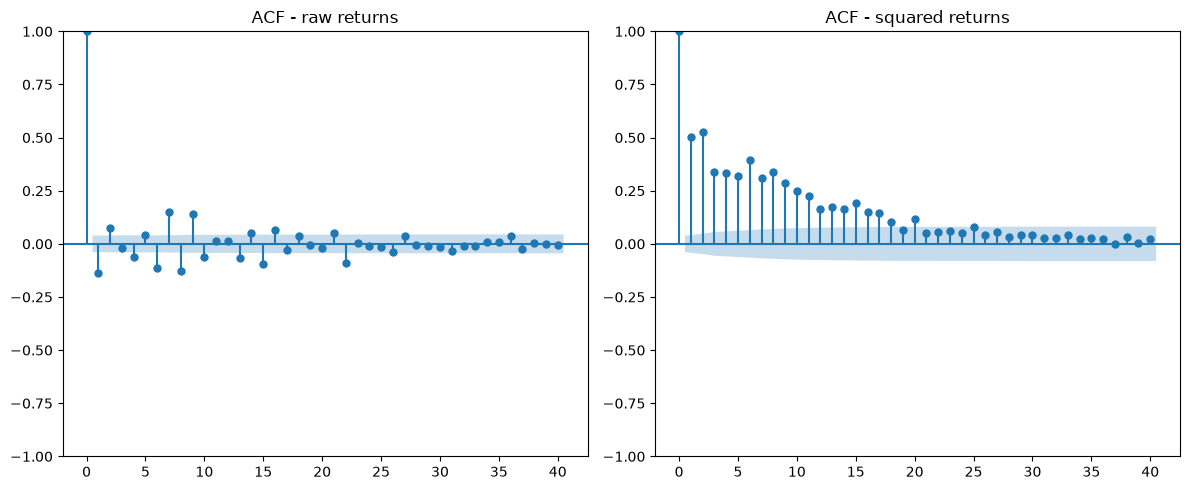

In [ ]:
from statsmodels.graphics.tsaplots import plot_acf

series = returns.set_index('date')['simple_return']
#it sets the date as index of my series named "series" with only simple_returns as values.

sq_series = series ** 2

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
plot_acf(series, lags=40, ax=axes[0], title='ACF - raw returns')
plot_acf(sq_series, lags=40, ax=axes[1], title='ACF - squared returns')


plt.tight_layout()
plt.show()

The first correlation is the maximum 1 because it is asking if my value at t0 is correlated to my value at t0. So, that's why the 100%.

The left graph asks whether returns themselves are correlated over time.
    Most of the autocorrelations after lag 0 are relatively close to zero, although there are some significant spikes at individual lags (for example, around lags 7–9).
    This suggests some autocorrelation in the returns at those particular lags, but there isn't a very strong and persistent pattern between today's return and past returns.

The right graph asks whether large/small returns today are related to large/small returns in the past?
    There's a strong pattern of autocorrelation in squared returns, that decays slowly.
    This suggests that the magnitude of returns is persistent over time, even though the returns themselves aren't strongly persistent. This is compatible with the phenomenon that is commonly called volatility clustering. Large movements tend to be followed by large movements, and small movements tend to be followed by small movements, without a direction prediction.

The light-blue region represents an approximate confidence interval around zero autocorrelation.
If an autocorrelation bar sticks outside the shaded region, there's evidence that the autocorrelation is statistically different from zero at the chosen confidence level.

In the left graph, the raw-return ACF has several statistically significant individual autocorrelations (sit outside the blue area), but the spikes are relatively small and irregular, not showing a clear pattern, so there isn't an obvious persistent autocorrelation structure.

In the right graph, many of the squared-return autocorrelations are outside the band, especially at the beginning. That's strong evidence that the squared returns are autocorrelated and not simply random noise.

Conclusion: Raw returns show some statistically noticeable autocorrelations at individual lags, but they are relatively small and do not display the strong, persistent pattern seen in squared returns.

#### 6.6 Sanity checks:

Same checks as the SQL track: row counts add up, no weekend rows, no impossible min/max/stddev.

In [ ]:
print('total dow groups n_obs vs n_obs ungrouped:',dow_stats['n_obs'].sum(), "Vs", len(returns))
print('total month groups n_obs vs n_obs ungrouped:',month_stats['n_obs'].sum(), "Vs", len(returns))
print('number of weekend days in DOW df:',dow_stats['day_of_week'].isin([5, 6]).sum())
print('how many day groups in my DOW df (supposed to be 5):',len(dow_stats))
print('how many month groups in my Month df (supposed to be 12):',len(month_stats))
print('how many negative stddev_return in DOW df:',(dow_stats['stddev_return'] < 0).any().sum())
print('any min_return higher than max_return in DOW df:',(dow_stats['min_return'] > dow_stats['max_return']).any())
print('how many negative stddev_return in Month df:',(month_stats['stddev_return'] < 0).any().sum())
print('any min_return higher than max_return in Month df:',(month_stats['min_return'] > month_stats['max_return']).any())


total dow groups n_obs vs n_obs ungrouped: 2516 Vs 2516
total month groups n_obs vs n_obs ungrouped: 2516 Vs 2516
number of weekend days in DOW df: 0
how many day groups in my DOW df (supposed to be 5): 5
how many month groups in my Month df (supposed to be 12): 12
how many negative stddev_return in DOW df: 0
any min_return higher than max_return in DOW df: False
how many negative stddev_return in Month df: 0
any min_return higher than max_return in Month df: False


#### 6.7 Saving outputs

In [ ]:
destination = Path(r"filepath\csv_stats")

dow_stats.to_csv(destination / 'market_dow_stats.csv', index=False)
month_stats.to_csv(destination / 'market_month_stats.csv', index=False)


Improvements:

Adding confidence intervals and effect sizes would be the natural next layer if I needed to quantify how precise those gaps are.